# B7 – Trích xuất đặc trưng theo chiều dọc
**Giai đoạn C – Phân tích & Khai phá** · Phương pháp: [`B07_TRICH_XUAT_DAC_TRUNG.md`](../QUY_TRINH_DU_AN/GIAI_DOAN_C_PHAN_TICH_KHAI_PHA/B07_TRICH_XUAT_DAC_TRUNG.md)

Đặc trưng được tạo bằng script `python -m src.analysis.features` (code: `src/analysis/features.py`, kiểm thử: `tests/test_features.py`, gồm test "xóa kỳ cuối, đặc trưng các kỳ trước không đổi").
Notebook này **kiểm tra tín hiệu** của các đặc trưng trên tập có nhãn (`Censored = 0`), làm căn cứ cho B9 – B11.

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

from src.analysis.features import feature_spec, signal_table

sns.set_theme(style="whitegrid", font_scale=0.95)
FIG_DIR = ROOT / "reports" / "figures"
C_BASE, C_LONG = "#8C8C8C", "#C44E52"

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=110, bbox_inches="tight")

feats = pd.read_parquet(ROOT / "data" / "features" / "feature_table.parquet")
spec = json.loads((ROOT / "config" / "feature_spec.json").read_text(encoding="utf-8"))
assert spec == feature_spec(), "feature_spec.json lệch với code, hãy chạy lại python -m src.analysis.features"
T = spec["target"]
lab = feats[feats["Censored"] == 0]
print(f"Bảng đặc trưng: {feats.shape[0]:,} dòng × {feats.shape[1]} cột")
print(f"{len(spec['features'])} đặc trưng = {len(spec['baseline_features'])} gốc + {len(spec['longitudinal_features'])} chiều dọc")
print("Chiều dọc:", ", ".join(spec["longitudinal_features"]))

Bảng đặc trưng: 79,239 dòng × 47 cột
43 đặc trưng = 20 gốc + 23 chiều dọc
Chiều dọc: GPA_prev, Attendance_prev, LMS_prev, Stress_prev, Work_prev, Delta_GPA, Delta_Attendance, Delta_LMS, Delta_Stress, Delta_Work_Hours, Cum_Failed_Courses, Cum_Advising_Visits, Cum_Emergency_Expense, Num_Emergency_Sems, CGPA, GPA_Roll3, Attendance_Roll3, GPA_Slope, Financial_Burden_Index, Tuition_to_Income, Failed_Ratio, Has_Emergency, Is_First_Semester


## 1. Giá trị thiếu

In [2]:
miss = feats[spec["numeric"] + spec["binary"]].isna().mean().mul(100).round(2)
miss = miss[miss > 0].sort_values(ascending=False)
print(f"Tỷ lệ dòng kỳ 1: {(feats['Semester'] == 1).mean():.2%}")
miss.to_frame("thieu_%")

Tỷ lệ dòng kỳ 1: 25.24%


,thieu_%
LMS_prev,25.46
Delta_LMS,25.46
Delta_Attendance,25.27
Attendance_prev,25.27
GPA_Slope,25.24
Work_prev,25.24
Delta_GPA,25.24
Stress_prev,25.24
GPA_prev,25.24
Delta_Stress,25.24


**Nhận xét:**
* Các cột Lag / Delta / `GPA_Slope` thiếu **25,24%**, đúng bằng tỷ lệ dòng kỳ 1 (20.000 / 79.239). Kỳ đầu không có kỳ trước, và cờ `Is_First_Semester` cho mô hình biết điều này.
* `LMS_*` thiếu thêm một chút (25,46%) do `LMS_Logins` còn 209 ô trống sau B4. `Attendance*` thiếu thêm 25 ô do mã lỗi −2 rơi vào kỳ 1.
* `Family_Income` và các chỉ số tài chính dựa trên nó thiếu 0,27% (199 sinh viên không khai báo).
* Tất cả được xử lý ở B10: XGBoost / LightGBM dùng trực tiếp `NaN`; LogReg / RF điền trung vị học từ tập Train.

## 2. Tín hiệu đơn biến: Spearman và Mutual Information

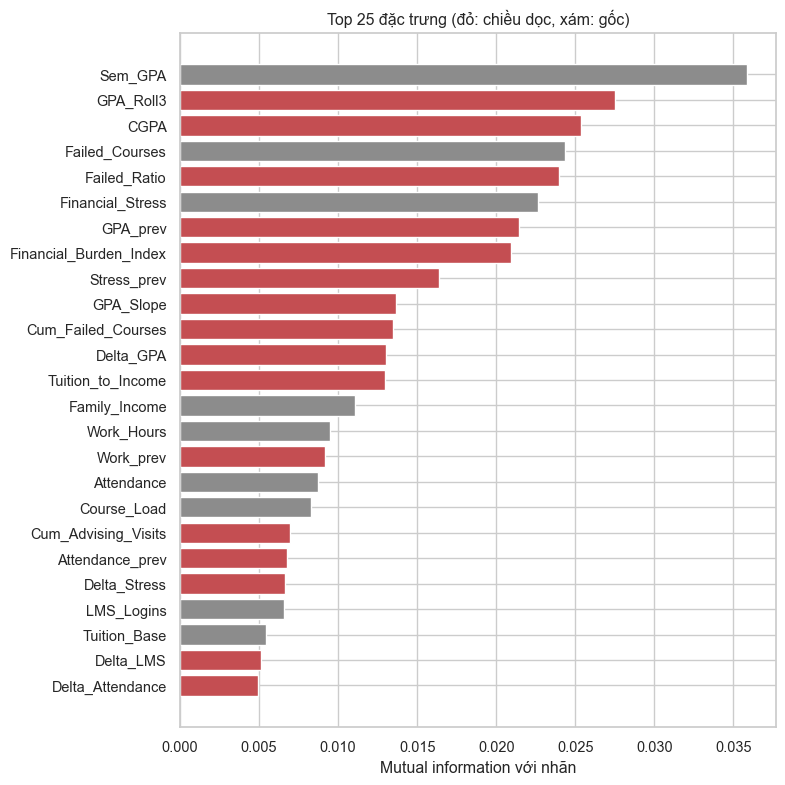

Tổng MI theo nhóm: {'chiều dọc': 0.2427, 'gốc': 0.1539}
Số đặc trưng chiều dọc trong top 10: 7


,spearman,abs,thieu_%,nhom,MI,hang_MI
Sem_GPA,-0.243,0.243,0.00,gốc,0.0359,1
GPA_Roll3,-0.223,0.223,0.00,chiều dọc,0.0275,2
CGPA,-0.215,0.215,0.00,chiều dọc,0.0254,3
Failed_Courses,0.203,0.203,0.00,gốc,0.0244,4
Failed_Ratio,0.190,0.190,0.00,chiều dọc,0.0240,5
Financial_Stress,0.194,0.194,0.00,gốc,0.0227,6
GPA_prev,-0.199,0.199,25.24,chiều dọc,0.0215,7
Financial_Burden_Index,0.178,0.178,0.27,chiều dọc,0.0209,8
Stress_prev,0.174,0.174,25.24,chiều dọc,0.0164,9
GPA_Slope,-0.118,0.118,25.24,chiều dọc,0.0137,10


In [3]:
cols = spec["numeric"] + spec["binary"]
X = lab[cols].astype(float).fillna(-999)  # MI cần giá trị số; -999 tách riêng nhóm thiếu
mi = mutual_info_classif(X, lab[T], discrete_features=[c in spec["binary"] for c in cols], random_state=42)
signals = signal_table(feats).join(pd.Series(mi, index=cols, name="MI")).sort_values("MI", ascending=False)
signals["hang_MI"] = range(1, len(signals) + 1)

top = signals.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top.index, top["MI"], color=[C_LONG if g == "chiều dọc" else C_BASE for g in top["nhom"]])
ax.set_xlabel("Mutual information với nhãn")
ax.set_title("Top 25 đặc trưng (đỏ: chiều dọc, xám: gốc)")
save(fig, "feat_signal.png"); plt.show()
print("Tổng MI theo nhóm:", signals.groupby("nhom")["MI"].sum().round(4).to_dict())
print("Số đặc trưng chiều dọc trong top 10:", int((signals.head(10)["nhom"] == "chiều dọc").sum()))
signals.round(4)

**Nhận xét:**
* **7 / 10** đặc trưng mạnh nhất theo mutual information là đặc trưng chiều dọc: `GPA_Roll3`, `CGPA`, `Failed_Ratio`, `GPA_prev`, `Financial_Burden_Index`, `Stress_prev`, `GPA_Slope`.
* Spearman chỉ đo quan hệ **đơn điệu** nên đánh giá thấp `Delta_Stress` (ρ = 0,05). Mutual information bắt được quan hệ phi tuyến (xem mục 3).
* Nhóm biến cố tài chính (`Emergency_Expense`, `Has_Emergency`, `Num_Emergency_Sems`, `Cum_Emergency_Expense`) gần như **không có tín hiệu** (MI ≈ 0), khớp với EDA. Vẫn giữ lại, để thí nghiệm ablation và SHAP ở B11 / B13 quyết định.
* **Thận trọng:** đây là tín hiệu **đơn biến**. Nhiều đặc trưng chiều dọc trùng thông tin với đặc trưng gốc (mục 4), nên giá trị **thêm vào** phải được đo bằng ablation ở B11 (chỉ đặc trưng gốc so với gốc + chiều dọc).

## 3. Quan hệ phi tuyến: tỷ lệ bỏ học theo nhóm ngũ phân vị

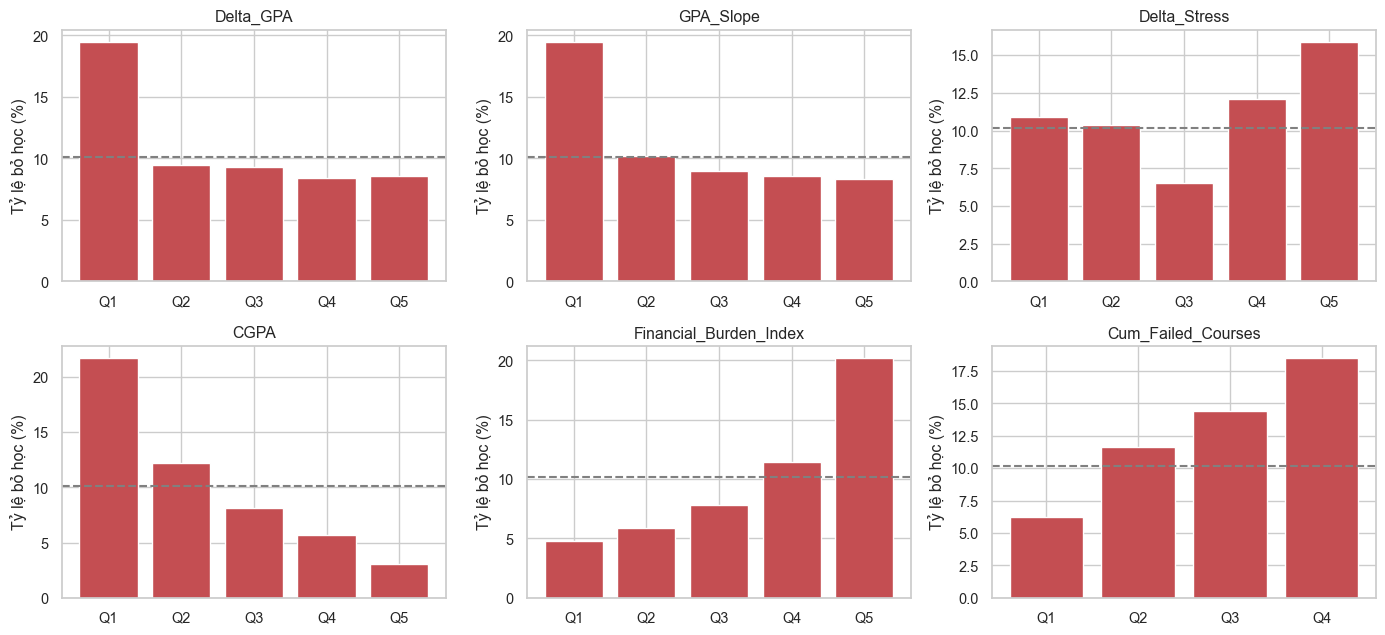

,Delta_GPA,GPA_Slope,Delta_Stress,CGPA,Financial_Burden_Index,Cum_Failed_Courses
nhom_phan_vi,,,,,,
0,19.5,19.5,10.9,21.7,4.8,6.2
1,9.5,10.2,10.4,12.2,5.9,11.6
2,9.3,9.0,6.5,8.1,7.8,14.4
3,8.4,8.6,12.1,5.7,11.4,18.5
4,8.6,8.3,15.9,3.1,20.2,NaN


In [4]:
show = ["Delta_GPA", "GPA_Slope", "Delta_Stress", "CGPA", "Financial_Burden_Index", "Cum_Failed_Courses"]
fig, axes = plt.subplots(2, 3, figsize=(14, 6.5))
tables = {}
for ax, col in zip(axes.flat, show):
    s = lab.dropna(subset=[col])
    t = s.groupby(pd.qcut(s[col], 5, duplicates="drop"), observed=True)[T].mean().mul(100).round(1)
    tables[col] = t
    ax.bar(range(len(t)), t.values, color=C_LONG)
    ax.axhline(lab[T].mean() * 100, color="gray", ls="--")
    ax.set_xticks(range(len(t)), [f"Q{i + 1}" for i in range(len(t))])
    ax.set_title(col); ax.set_ylabel("Tỷ lệ bỏ học (%)")
save(fig, "feat_binned_rates.png"); plt.show()
pd.DataFrame({k: v.reset_index(drop=True) for k, v in tables.items()}, index=None).rename_axis("nhom_phan_vi")

**Nhận xét** (Q1 = nhóm giá trị thấp nhất):
* **`Delta_GPA` / `GPA_Slope`:** chỉ nhóm sụt mạnh nhất (Q1, GPA giảm > 0,22) có rủi ro gần gấp đôi (**19,5%**); các nhóm còn lại quanh 8 – 10%. Đây là quan hệ **ngưỡng**, mô hình cây bắt tốt hơn mô hình tuyến tính.
* **`Delta_Stress`** có dạng **chữ U**: áp lực ổn định → 6,5%; tăng mạnh → **15,9%**; giảm mạnh cũng → 10,9%. Biến động tài chính theo cả hai chiều đều là dấu hiệu bất ổn. Đó là lý do Spearman gần 0 nhưng mutual information vẫn > 0.
* **`CGPA`:** giảm đều từ **21,7%** (CGPA thấp nhất) xuống **3,1%** (cao nhất), chênh nhau khoảng 7 lần.
* **`Financial_Burden_Index`:** tăng đều từ 4,8% lên **20,2%**.
* **`Cum_Failed_Courses`:** tăng đều từ 6,2% lên **18,5%**.

## 4. Trùng lặp thông tin giữa các đặc trưng

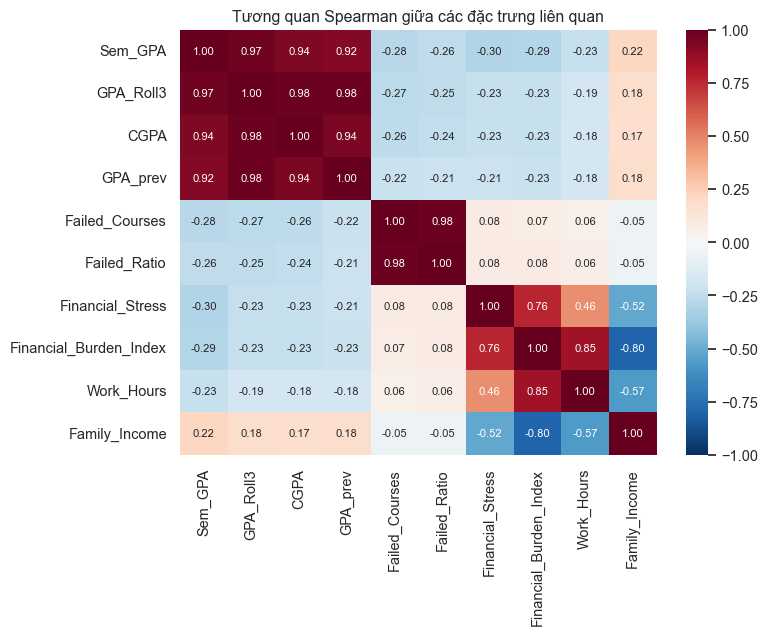

In [5]:
group = ["Sem_GPA", "GPA_Roll3", "CGPA", "GPA_prev", "Failed_Courses", "Failed_Ratio",
         "Financial_Stress", "Financial_Burden_Index", "Work_Hours", "Family_Income"]
corr = lab[group].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8}, ax=ax)
ax.set_title("Tương quan Spearman giữa các đặc trưng liên quan")
save(fig, "feat_redundancy.png"); plt.show()

**Nhận xét:**
* Nhóm GPA gần như trùng nhau: `Sem_GPA` – `GPA_Roll3` 0,97; `GPA_Roll3` – `CGPA` 0,98; `GPA_Roll3` – `GPA_prev` 0,98.
* `Failed_Courses` – `Failed_Ratio` 0,98 (hầu hết sinh viên học 15 tín chỉ). `Financial_Stress` – `Financial_Burden_Index` 0,76.
* **Hệ quả:**
  * **Mô hình cây** (RF, XGBoost, LightGBM) chịu được các đặc trưng trùng nhau, nên giữ nguyên.
  * **LogReg:** regularization L2 giúp ổn định, nhưng **không** diễn giải từng hệ số riêng lẻ.
  * **SHAP (B13):** đóng góp sẽ bị chia giữa các đặc trưng trùng nhau, nên khi đọc cần **cộng theo nhóm** (ví dụ "nhóm GPA").

## 5. Kết luận cho các bước sau

| Kết luận | Áp dụng ở |
|---|---|
| Đặc trưng chiều dọc chiếm 7 / 10 vị trí đầu theo mutual information | Ablation ở B11: gốc so với gốc + chiều dọc |
| Quan hệ ngưỡng (`Delta_GPA`, `GPA_Slope`) và chữ U (`Delta_Stress`) | Ưu tiên mô hình cây; LogReg chỉ làm baseline |
| Thiếu 25% ở Lag / Delta là có chủ đích (kỳ 1) | B10: XGBoost / LightGBM dùng `NaN`; mô hình khác điền trung vị từ Train |
| Nhóm GPA, nhóm môn trượt trùng thông tin | Không loại ngay; đọc SHAP theo nhóm ở B13 |
| Nhóm biến cố tài chính gần như không có tín hiệu | Giữ lại, xem lại sau ablation / SHAP |